# 03 · Análise de sentimentos com FinBERT-PT-BR

Entrega da Etapa 2 (22/10). O notebook:

1. carrega as manchetes revisadas (`data/teste_revisao.csv`, montada a partir da coleta do notebook 01);
2. classifica cada uma como **boa, ruim ou neutra para o acionista** com o modelo pré-treinado FinBERT-PT-BR (`lucas-leme/FinBERT-PT-BR`), sem ajuste;
3. testa exemplos de cada classe, inclusive manchetes escritas por nós;
4. registra os erros e termina com uma breve análise.

Os rótulos das manchetes foram sugeridos por IA generativa (Claude) e revisados por nós seguindo o guia de rotulagem (`Entregas/27-10-2026/guia_rotulagem.md`).

**Como rodar:** abra no VS Code ou no Jupyter e execute tudo. Roda em CPU. O resultado vai para `Entregas/27-10-2026/resultado_sentimentos.csv`.

In [1]:
from pathlib import Path

DADOS = Path("../data")
SAIDA = Path("../Entregas/27-10-2026")

## Manchetes

In [2]:
import pandas as pd

ROTULOS = ["boa", "neutra", "ruim"]

manchetes = pd.read_csv(DADOS / "teste_revisao.csv")
manchetes["rotulo"] = manchetes["rotulo"].str.strip().str.lower()

invalidos = manchetes[~manchetes["rotulo"].isin(ROTULOS + ["descartar"])]
assert invalidos.empty, f"Rótulos inválidos nas linhas: {invalidos['id'].tolist()}"

manchetes = manchetes[manchetes["rotulo"] != "descartar"].reset_index(drop=True)
print(f"{len(manchetes)} manchetes")
manchetes["rotulo"].value_counts().to_frame("manchetes")

200 manchetes


,manchetes
rotulo,
neutra,96
boa,76
ruim,28


## Classificação com FinBERT-PT-BR

In [3]:
import torch
from transformers import pipeline

device = 0 if torch.cuda.is_available() else -1
clf = pipeline("text-classification", model="lucas-leme/FinBERT-PT-BR", device=device)
MAPA = {"POSITIVE": "boa", "NEGATIVE": "ruim", "NEUTRAL": "neutra"}


def classifica(textos):
    saidas = clf(list(textos), batch_size=32, truncation=True)
    return [MAPA[s["label"]] for s in saidas], [round(s["score"], 2) for s in saidas]


manchetes["previsto"], manchetes["confianca"] = classifica(manchetes["manchete"])
manchetes["acertou"] = manchetes["rotulo"] == manchetes["previsto"]

pd.set_option("display.max_colwidth", 110)
print(f"Acertou {manchetes['acertou'].sum()} de {len(manchetes)}")
manchetes[["empresa", "manchete", "rotulo", "previsto", "confianca"]].head(10)

Acertou 112 de 200


,empresa,manchete,rotulo,previsto,confianca
0,SANB11,"Santander Brasil (SANB11) aprova JCP de R$ 0,40 por unit",boa,neutra,0.56
1,BBAS3,Banco do Brasil (BBAS3) Antecipa R$ 197 Milhões em JCP; Veja Quem Recebe e Quando Cai na Conta,boa,neutra,0.53
2,SANB11,Santander prossegue com OPA voluntária e pede à CVM registro de emissor estrangeiro,boa,neutra,0.69
3,EMBR3,Embraer (EMBJ3): comprar agora ou esperar uma queda?,neutra,neutra,0.53
4,BPAC11,BTG (BPAC11) recebe licença para operar como banco no Peru,boa,neutra,0.52
5,SBSP3,"Valor 1000: Sabesp, líder do setor de água, saneamento e serviços ambientais, acelera para antecipar metas",boa,boa,0.64
6,SBSP3,Obras da Sabesp provocam nova interdição temporária na Maranduba,neutra,ruim,0.85
7,BPAC11,Gestora alemã AllianzGI fecha acordo de distribuição com BTG Pactual Asset,boa,neutra,0.52
8,BBAS3,JP Morgan 'manda vender' ação do Banco do Brasil (BBAS3) após rali eleitoral — e elege outro bancão para c...,ruim,ruim,0.76
9,VIVT3,Telefônica Brasil vai incorporar a subsidiária FiBrasil,neutra,neutra,0.63


## Métricas por classe

A acurácia esconde o desbalanceamento: 96 das 200 manchetes são neutras. O professor pede precisão, revocação e F1, e o **F1 macro** (média simples do F1 das três classes) é a métrica que usamos para comparar modelos daqui em diante, porque dá o mesmo peso à classe `ruim`, que tem só 28 manchetes.

              precision    recall  f1-score   support

         boa      0.586     0.447     0.507        76
      neutra      0.640     0.573     0.604        96
        ruim      0.411     0.821     0.548        28

    accuracy                          0.560       200
   macro avg      0.545     0.614     0.553       200
weighted avg      0.587     0.560     0.560       200

F1 macro: 0.553


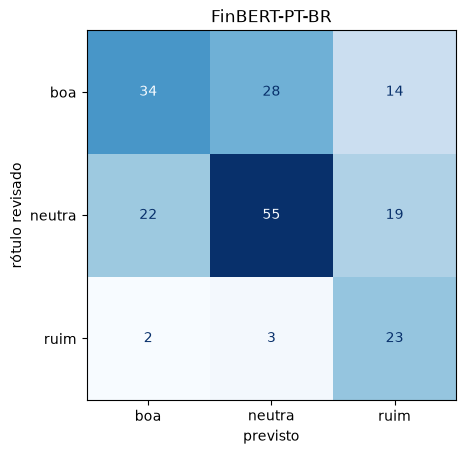

In [4]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay, classification_report, f1_score

print(classification_report(manchetes["rotulo"], manchetes["previsto"], labels=ROTULOS, digits=3, zero_division=0))
print(f"F1 macro: {f1_score(manchetes['rotulo'], manchetes['previsto'], average='macro'):.3f}")

ConfusionMatrixDisplay.from_predictions(manchetes["rotulo"], manchetes["previsto"], labels=ROTULOS,
                                        colorbar=False, cmap="Blues")
plt.title("FinBERT-PT-BR")
plt.xlabel("previsto")
plt.ylabel("rótulo revisado")
plt.show()

## Exemplos por classe

Para cada rótulo, alguns acertos e alguns erros.

In [5]:
for r in ROTULOS:
    da_classe = manchetes[manchetes["rotulo"] == r]
    ok, erro = da_classe[da_classe["acertou"]], da_classe[~da_classe["acertou"]]
    print(f"=== {r} ({len(ok)} de {len(da_classe)} certas) ===")
    for _, l in pd.concat([ok.sample(min(3, len(ok)), random_state=0),
                           erro.sample(min(2, len(erro)), random_state=0)]).iterrows():
        print(f"{'OK  ' if l['acertou'] else 'ERRO'} previsto={l['previsto']:<6} {l['manchete']}")
    print()

=== boa (34 de 76 certas) ===
OK   previsto=boa    WEG (WEGE3) vira uma das melhores geradoras de valor no longo prazo; ações disparam
OK   previsto=boa    BTG Pactual registra lucro recorde de R$ 4,9 bilhões no 2T26, alta de 22,2%
OK   previsto=boa    RD Saúde (RADL3) registra lucro de R$ 432 milhões no 2T26, alta anual de 7,4%
ERRO previsto=ruim   Ambev (ABEV3) sobe contra o Ibovespa; caixa robusto sustenta leitura defensiva
ERRO previsto=neutra STF homologa acordo entre governo e Axia Energia, antiga Eletrobras

=== neutra (55 de 96 certas) ===
OK   previsto=neutra Edital de Leilão ITAÚ UNIBANCO S/A
OK   previsto=neutra Santander quer comprar sua fatia de SANB11: vale pegar o prêmio de 15% da OPA e pular fora, ou a matriz está fazendo o melhor negócio da mesa?
OK   previsto=neutra PRIO S.A (PRIO3) Comparação de Concorrentes Divulgados Publicamente
ERRO previsto=ruim   Leilão do Bradesco pode reduzir lances em até R$ 263 mil; casa em Feira de Santana está na lista
ERRO previsto=ruim 

### Manchetes escritas por nós

Casos controlados, incluindo o exemplo da proposta, em que o tom da frase e o efeito para o acionista apontam para lados diferentes.

In [6]:
exemplos = pd.DataFrame([
    ("Itaú lucra R$ 12 bilhões no trimestre e supera expectativas", "boa"),
    ("Petrobras anuncia pagamento de R$ 20 bilhões em dividendos", "boa"),
    ("Petrobras reajusta o preço da gasolina nas refinarias", "boa"),        # ruim para o consumidor, boa para o acionista
    ("Bradesco é condenado a pagar multa milionária ao Procon", "ruim"),
    ("Ações da Ambev despencam após resultado abaixo do esperado", "ruim"),
    ("Localiza corta 2 mil vagas e fecha lojas para reduzir custos", "boa"),  # tom negativo, mas corte de custos tende a agradar o acionista
    ("WEG abre inscrições para programa de estágio", "neutra"),
    ("Vale realiza assembleia de acionistas nesta sexta-feira", "neutra"),
], columns=["manchete", "esperado"])

exemplos["previsto"], exemplos["confianca"] = classifica(exemplos["manchete"])
exemplos["acertou"] = exemplos["esperado"] == exemplos["previsto"]
exemplos

,manchete,esperado,previsto,confianca,acertou
0,Itaú lucra R$ 12 bilhões no trimestre e supera expectativas,boa,boa,0.73,True
1,Petrobras anuncia pagamento de R$ 20 bilhões em dividendos,boa,neutra,0.61,False
2,Petrobras reajusta o preço da gasolina nas refinarias,boa,neutra,0.56,False
3,Bradesco é condenado a pagar multa milionária ao Procon,ruim,ruim,0.84,True
4,Ações da Ambev despencam após resultado abaixo do esperado,ruim,ruim,0.84,True
5,Localiza corta 2 mil vagas e fecha lojas para reduzir custos,boa,ruim,0.85,False
6,WEG abre inscrições para programa de estágio,neutra,neutra,0.69,True
7,Vale realiza assembleia de acionistas nesta sexta-feira,neutra,neutra,0.71,True


## Erros

In [7]:
erros = manchetes[~manchetes["acertou"]]
print(f"{len(erros)} erros de {len(manchetes)}\n")
print("Rótulo esperado x previsto nos erros:")
print(erros.groupby(["rotulo", "previsto"]).size().to_string())
erros[["empresa", "manchete", "rotulo", "previsto", "confianca"]].sort_values("confianca", ascending=False)

88 erros de 200

Rótulo esperado x previsto nos erros:
rotulo  previsto
boa     neutra      28
        ruim        14
neutra  boa         22
        ruim        19
ruim    boa          2
        neutra       3


,empresa,manchete,rotulo,previsto,confianca
6,SBSP3,Obras da Sabesp provocam nova interdição temporária na Maranduba,neutra,ruim,0.85
103,SBSP3,Manutenção da Sabesp pode afetar abastecimento de água,neutra,ruim,0.85
114,SBSP3,Sabesp registra mais de 20 mil furtos de hidrômetros em São Paulo,neutra,ruim,0.84
121,ELET3,STF suspende analise de acordo entre União e Eletrobras sobre desestatização,neutra,ruim,0.84
166,VALE3,Vale sanciona Marcelo Gasparino por vazamento de informações confidenciais,neutra,ruim,0.84
...,...,...,...,...,...
117,VIVT3,"Telefônica Brasil (VIVT3), dona da Vivo, adquire Fibrasil por R$ 458,7 milhões",boa,neutra,0.41
14,WEGE3,WEG (WEGE3) explode após balanço; entenda o que animou a Bolsa,boa,ruim,0.40
102,PRIO3,PRIO (PRIO3) registra vitória em blocos Magnetita e Hematita da ANP,boa,neutra,0.38
161,VALE3,Vale conclui venda do controle de complexo de níquel no Canadá,neutra,ruim,0.36


In [8]:
arq = SAIDA / "resultado_sentimentos.csv"
manchetes[["id", "empresa", "manchete", "rotulo", "previsto", "confianca", "acertou"]].to_csv(arq, index=False)
print(f"Previsões salvas em {arq}")

Previsões salvas em ..\Entregas\27-10-2026\resultado_sentimentos.csv


## Breve análise

**Resultado.** O FinBERT-PT-BR acertou 112 de 200 manchetes (acurácia de 56%), com **F1 macro de 0,553**. Por classe: `ruim` tem revocação alta (0,82) e precisão baixa (0,41); `boa` é a pior classe (F1 0,51), porque o modelo só reconhece 45% das notícias boas.

**Onde erra.**
- **Trata como `ruim` notícias que consideramos neutras** (19 casos), quase sempre com confiança alta (~0,85): obras e manutenção ("Obras da Sabesp provocam nova interdição temporária na Maranduba"), decisões judiciais em andamento ("STJ avalia impacto de revisão de teses dos juros da Eletrobras") e assuntos trabalhistas ("Sindicato realiza protesto na agência do Bradesco").
- **Não reconhece proventos como notícia boa.** Das 15 manchetes sobre JCP ou dividendos rotuladas como `boa`, o modelo não acertou nenhuma: chamou 12 de `neutra` e 3 de `ruim` (ex.: "Santander Brasil (SANB11) aprova JCP de R$ 0,40 por unit" → neutra).
- **Notícias mistas:** em "Lucro da Ambev supera expectativa no 2T26, mas ação chega a cair 3%" o modelo segue o começo da frase (`boa`), enquanto o nosso guia manda seguir a reação do mercado (`ruim`).

**Por quê.** O FinBERT foi treinado para o retorno esperado a partir do tom do texto, e o nosso critério é o impacto provável para o acionista. Os dois divergem quando a frase tem tom negativo e efeito positivo para a empresa. Nas manchetes escritas por nós, o modelo acertou 5 de 8 e errou justamente esses casos: o reajuste da gasolina saiu `neutra`, o corte de 2 mil vagas da Localiza saiu `ruim` com 0,85 de confiança e o pagamento de dividendos saiu `neutra`.

**Limitações.** O modelo só vê a manchete, sem o texto da matéria. Os rótulos de referência foram sugeridos por IA e revisados por nós, o que pode puxar a revisão para concordar com a sugestão. Com só 28 manchetes `ruim`, as métricas dessa classe variam muito com poucos acertos ou erros.

**Próximo passo.** Esses erros são sistemáticos (proventos, obras, processos), então dá para corrigi-los com treino no nosso critério: o fine-tuning do BERTimbau previsto para a etapa de Transformers. A rede neural do notebook 05 testa se um modelo treinado do zero resolve.